In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
orig_df = pd.read_csv(r'D:\Udemy Courses\complete_data_science_machine_learning_dl_nlp_bootcamp\21-Regression Project\datasets\Algeria_forest_fires_datasets_cleaned_2.csv')
orig_df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [3]:
df = orig_df.drop(['day', 'month', 'year'], axis = 1)
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [4]:
df['Classes'].value_counts()

Classes
fire        138
not fire    106
Name: count, dtype: int64

In [5]:
df['Classes'] = df['Classes'].apply(lambda x: 0 if x == 'not fire' else 1)
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  244 non-null    int64  
 1   RH           244 non-null    int64  
 2   Ws           244 non-null    int64  
 3   Rain         244 non-null    float64
 4   FFMC         244 non-null    float64
 5   DMC          244 non-null    float64
 6   DC           244 non-null    float64
 7   ISI          244 non-null    float64
 8   BUI          244 non-null    float64
 9   FWI          244 non-null    float64
 10  Classes      244 non-null    int64  
 11  Region       244 non-null    int64  
dtypes: float64(7), int64(5)
memory usage: 23.0 KB


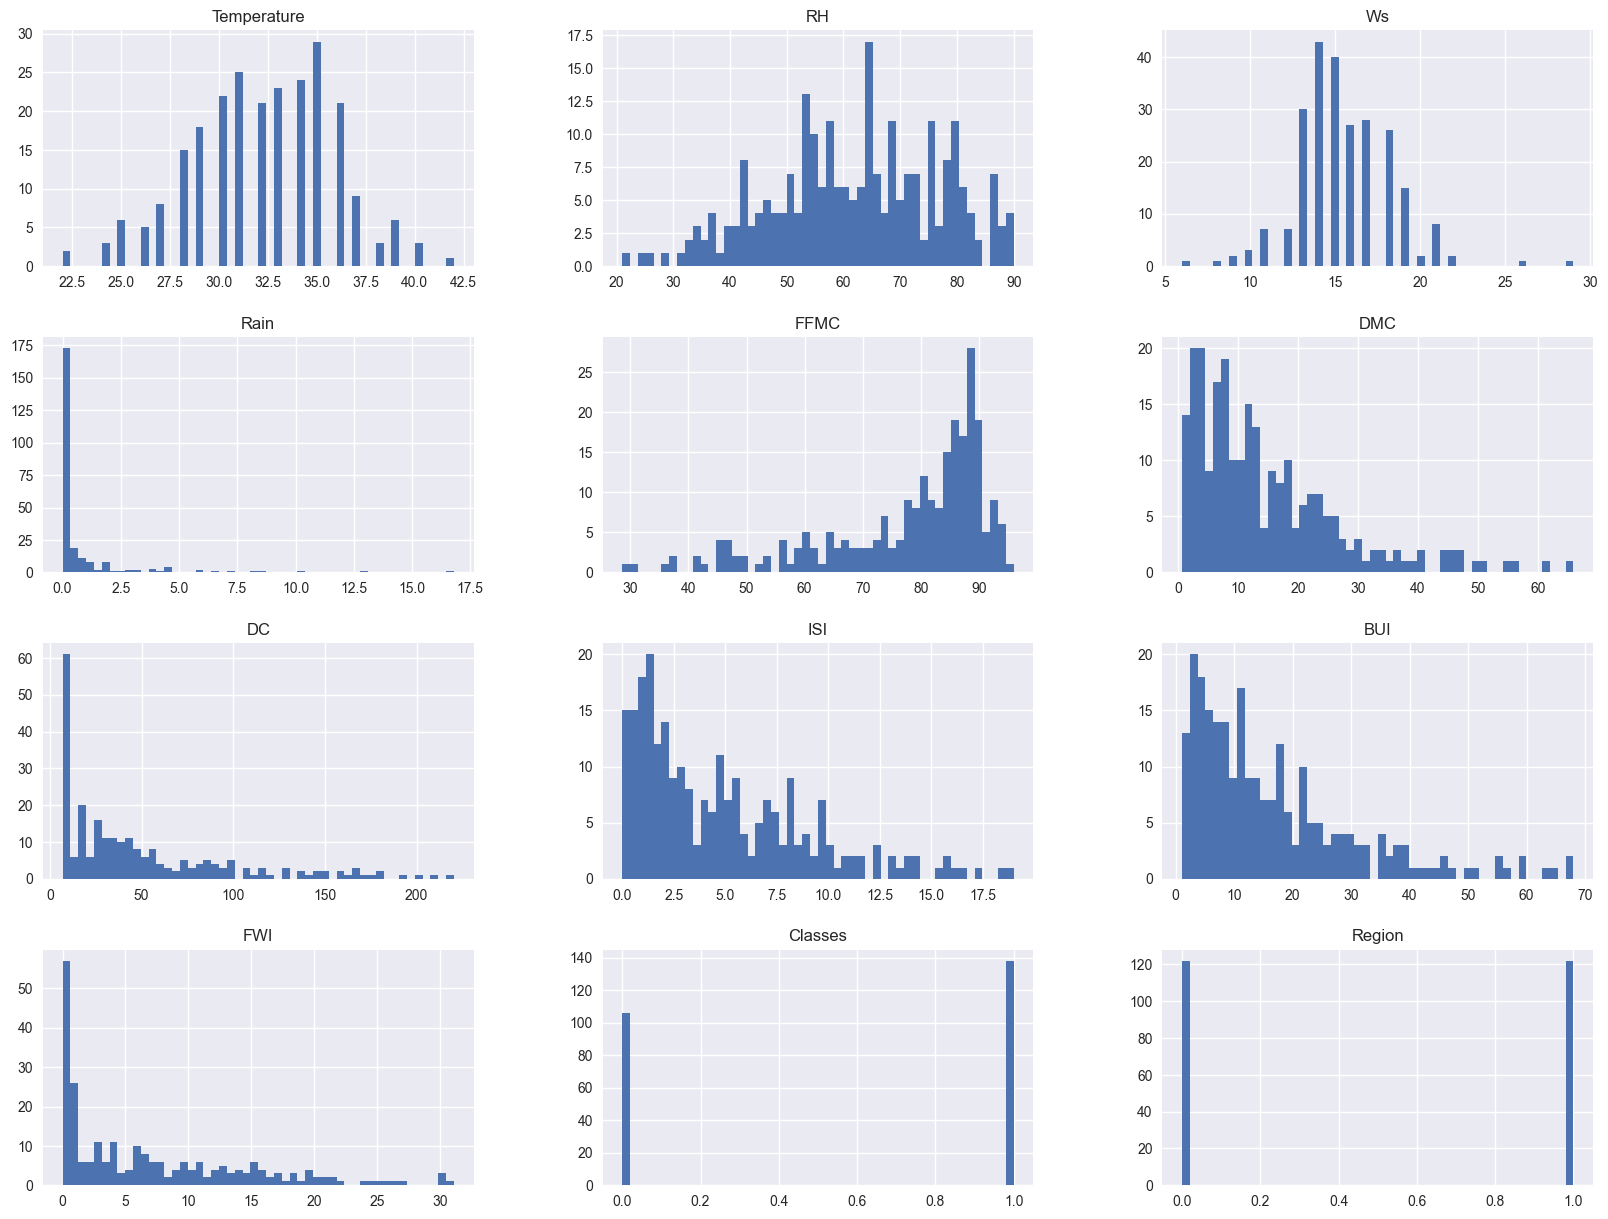

In [7]:
plt.style.use('seaborn-v0_8')
df.hist(bins = 50, figsize=(20, 15))
plt.show()

In [8]:
percentage = df['Classes'].value_counts(normalize=True)*100

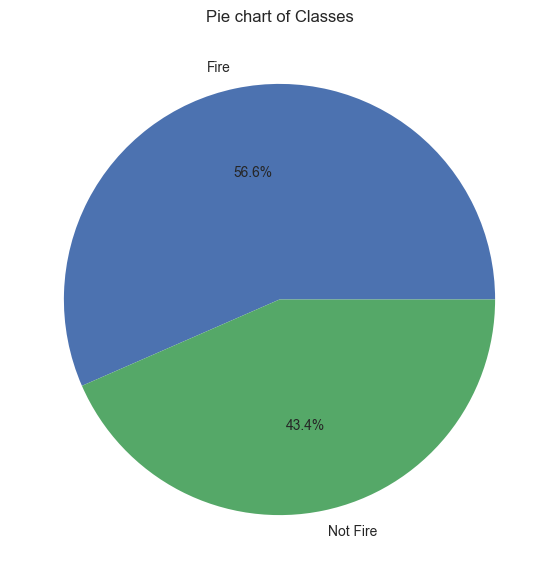

In [9]:
class_labels = ['Fire', 'Not Fire']
plt.figure(figsize=(12, 7))
plt.pie(percentage, labels=class_labels, autopct='%1.1f%%')
plt.title('Pie chart of Classes')
plt.show()

## Correlation

In [10]:
df.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
Temperature,1.000000,-0.654443,-0.278132,-0.326786,0.677491,0.483105,0.372942,0.607551,0.455504,0.562344,0.518119,0.273496
RH,-0.654443,1.000000,0.236084,0.222968,-0.645658,-0.405133,-0.223200,-0.690637,-0.348587,-0.574773,-0.435023,-0.406424
Ws,-0.278132,0.236084,1.000000,0.170169,-0.163255,-0.001246,0.077732,0.015248,0.029756,0.030910,-0.066529,-0.176829
Rain,-0.326786,0.222968,0.170169,1.000000,-0.544045,-0.288548,-0.297507,-0.347105,-0.299171,-0.323831,-0.379449,-0.041080
FFMC,0.677491,-0.645658,-0.163255,-0.544045,1.000000,0.602391,0.505571,0.739730,0.589652,0.688876,0.770114,0.224680
DMC,0.483105,-0.405133,-0.001246,-0.288548,0.602391,1.000000,0.875879,0.674499,0.982073,0.875791,0.584188,0.191094
DC,0.372942,-0.223200,0.077732,-0.297507,0.505571,0.875879,1.000000,0.502297,0.942005,0.739658,0.508956,-0.079962
ISI,0.607551,-0.690637,0.015248,-0.347105,0.739730,0.674499,0.502297,1.000000,0.635891,0.913163,0.735511,0.268421
BUI,0.455504,-0.348587,0.029756,-0.299171,0.589652,0.982073,0.942005,0.635891,1.000000,0.858065,0.583882,0.087370
FWI,0.562344,-0.574773,0.030910,-0.323831,0.688876,0.875791,0.739658,0.913163,0.858065,1.000000,0.716490,0.195070


<Axes: >

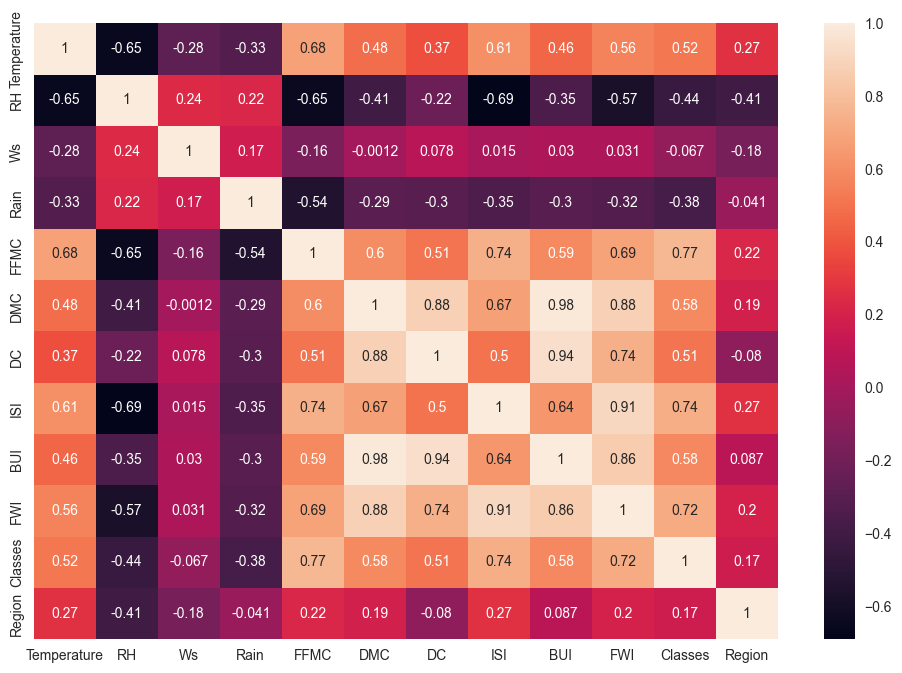

In [11]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True)

<Axes: ylabel='FWI'>

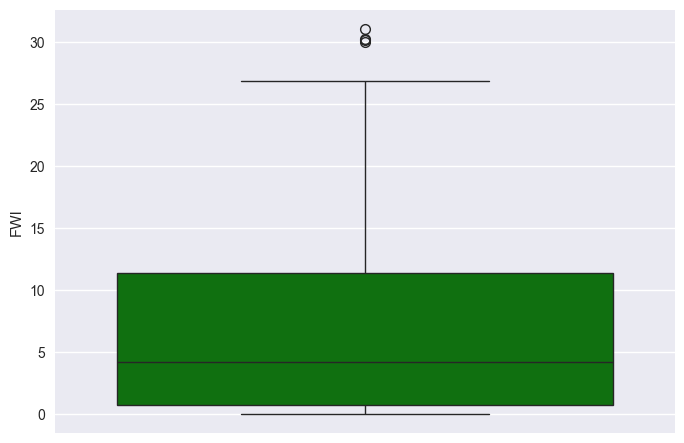

In [12]:
sns.boxplot(df['FWI'], color='green')

Text(0.5, 1.0, 'Fire Analysis of Sidi-Bel Regions')

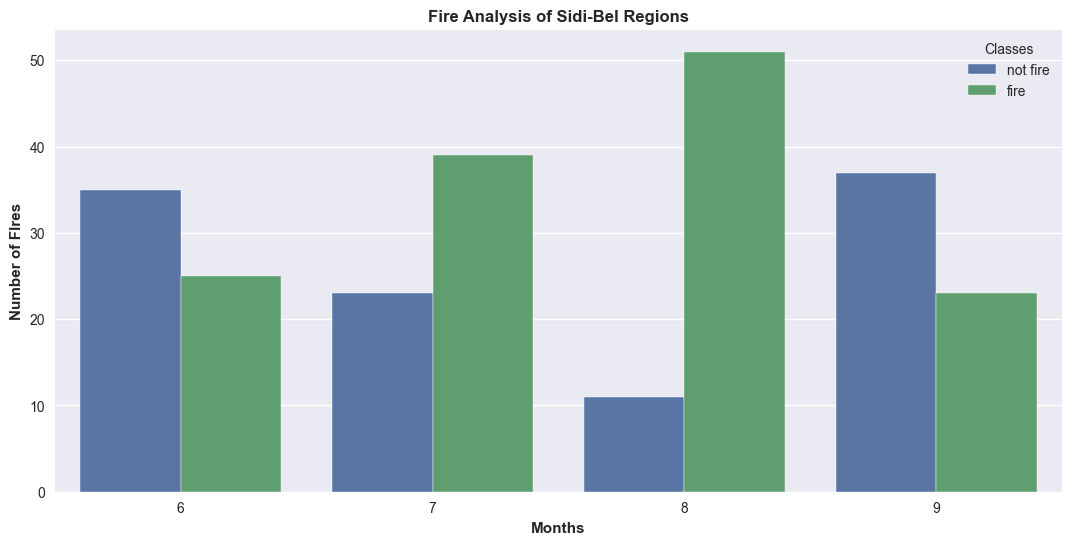

In [13]:
## Monthly Fire Analysis
df_temp = df.loc[df['Region'] == 1]
plt.subplots(figsize=(13, 6))
sns.set_style('whitegrid')
sns.countplot(x='month', hue='Classes', data=orig_df)
plt.ylabel('Number of FIres', weight='bold')
plt.xlabel('Months', weight='bold')
plt.title("Fire Analysis of Sidi-Bel Regions", weight='bold')

Text(0.5, 1.0, 'Fire Analysis of Bejaia Regions')

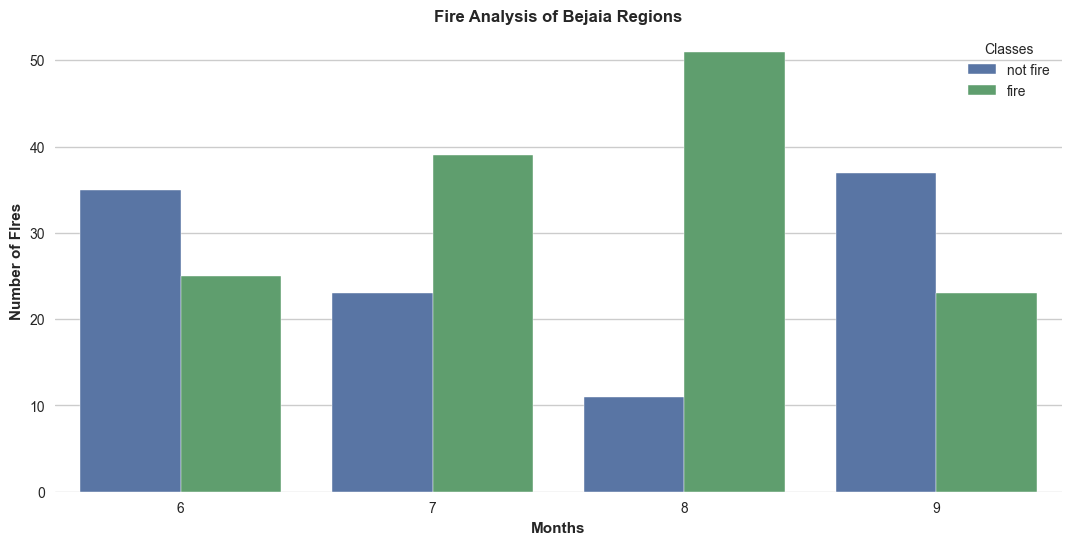

In [14]:
## Monthly Fire Analysis
df_temp = df.loc[df['Region'] == 0]
plt.subplots(figsize=(13, 6))
sns.set_style('whitegrid')
sns.countplot(x='month', hue='Classes', data=orig_df)
plt.ylabel('Number of FIres', weight='bold')
plt.xlabel('Months', weight='bold')
plt.title("Fire Analysis of Bejaia Regions", weight='bold')